## 1. Setup

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error,
                             mean_squared_error, r2_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

CITY, LAT, LON = "Hyderabad", 17.385, 78.4867
START_YEAR, END_YEAR = 2015, 2025
RAIN_THRESHOLD_MM = 1.0       # a day with >= 1 mm total rain counts as a rainy day
TRAIN_END = "2022-12-31"      # train up to here, test after (no shuffling!)

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

## 2. Get the data (Open-Meteo, free, no API key)
Downloads hourly data year by year, then caches it to `data/` so you only download once.

In [ ]:
CACHE = f"data/{CITY.lower()}_hourly.csv"
HOURLY_VARS = "temperature_2m,relative_humidity_2m,precipitation,surface_pressure,wind_speed_10m,cloud_cover"

def download_year(year):
    r = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={"latitude": LAT, "longitude": LON,
                "start_date": f"{year}-01-01", "end_date": f"{year}-12-31",
                "hourly": HOURLY_VARS, "timezone": "Asia/Kolkata"},
        timeout=120)
    r.raise_for_status()
    return pd.DataFrame(r.json()["hourly"])

if os.path.exists(CACHE):
    hourly = pd.read_csv(CACHE, parse_dates=["time"])
else:
    hourly = pd.concat([download_year(y) for y in range(START_YEAR, END_YEAR + 1)], ignore_index=True)
    hourly["time"] = pd.to_datetime(hourly["time"])
    hourly.to_csv(CACHE, index=False)

print(hourly.shape)
hourly.head()

(96432, 7)


,time,temperature_2m,relative_humidity_2m,precipitation,surface_pressure,wind_speed_10m,cloud_cover
0,2015-01-01 00:00:00,21.3,75,0.0,952.3,13.5,7
1,2015-01-01 01:00:00,20.8,78,0.0,952.0,12.9,10
2,2015-01-01 02:00:00,20.2,82,0.0,951.1,11.2,2
3,2015-01-01 03:00:00,19.6,86,0.0,951.2,11.8,7
4,2015-01-01 04:00:00,19.2,90,0.0,950.8,11.2,10


## 3. Clean and aggregate to daily data

In [ ]:
hourly["date"] = hourly["time"].dt.floor("D")
daily = hourly.groupby("date").agg(
    temp_max=("temperature_2m", "max"),
    temp_min=("temperature_2m", "min"),
    temp_mean=("temperature_2m", "mean"),
    humidity=("relative_humidity_2m", "mean"),
    pressure=("surface_pressure", "mean"),
    wind=("wind_speed_10m", "mean"),
    cloud=("cloud_cover", "mean"),
    rain=("precipitation", "sum"),
)
print("Missing values per column:")
print(daily.isna().sum())

# Small gaps: interpolate. Anything left over gets dropped later.
daily = daily.interpolate(limit=3)
daily.describe().round(2)

Missing values per column:
temp_max     0
temp_min     0
temp_mean    0
humidity     0
pressure     0
wind         0
cloud        0
rain         0
dtype: int64


,temp_max,temp_min,temp_mean,humidity,pressure,wind,cloud,rain
count,4018.00,4018.00,4018.00,4018.00,4018.00,4018.00,4018.00,4018.00
mean,31.15,21.36,25.90,62.68,953.38,10.36,53.53,2.42
std,3.66,3.27,3.14,16.88,3.72,4.58,35.53,6.05
min,20.10,11.00,17.34,17.58,941.77,2.78,0.00,0.00
25%,28.60,18.90,23.76,49.42,950.40,7.25,19.80,0.00
50%,30.10,22.20,25.47,63.38,953.51,8.91,53.19,0.00
75%,33.50,23.50,27.65,76.86,956.46,12.10,90.71,1.70
max,41.60,29.90,35.67,97.92,962.12,31.05,100.00,82.70


## 4. Exploratory data analysis

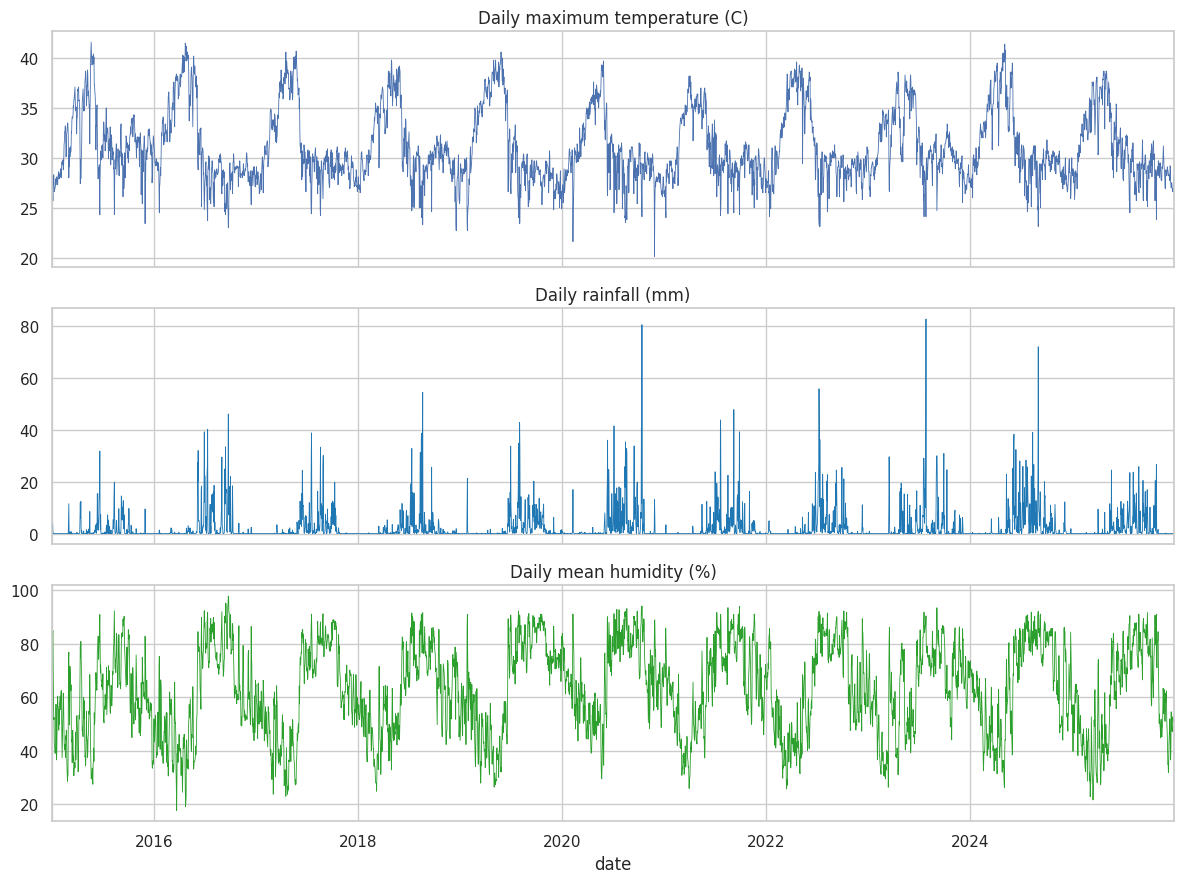

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
daily["temp_max"].plot(ax=axes[0], lw=0.6, title="Daily maximum temperature (C)")
daily["rain"].plot(ax=axes[1], lw=0.6, color="tab:blue", title="Daily rainfall (mm)")
daily["humidity"].plot(ax=axes[2], lw=0.6, color="tab:green", title="Daily mean humidity (%)")
plt.tight_layout(); plt.savefig("outputs/01_timeseries.png", dpi=150); plt.show()

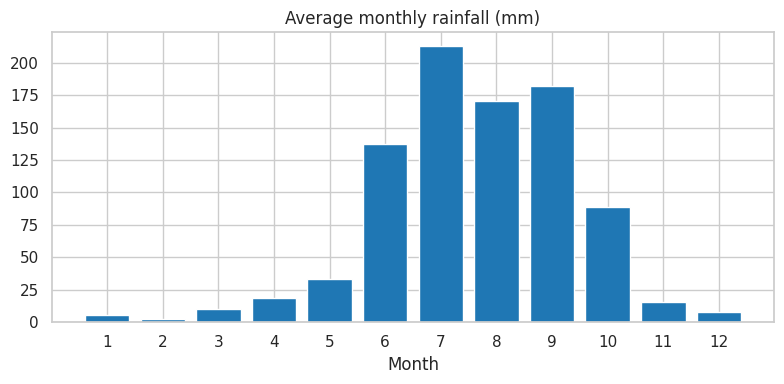

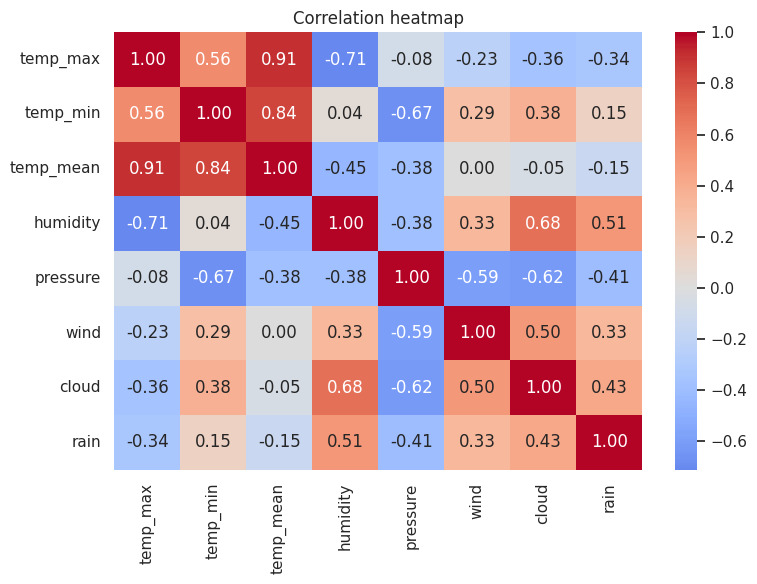

In [ ]:
n_years = daily.index.year.nunique()
monthly = (daily["rain"].groupby(daily.index.month.to_numpy()).sum() / n_years).reset_index(drop=True)
monthly.index = range(1, 13)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(monthly.index, monthly.values, color="tab:blue")
ax.set_title("Average monthly rainfall (mm)"); ax.set_xlabel("Month"); ax.set_xticks(range(1, 13))
plt.tight_layout(); plt.savefig("outputs/02_monthly_rain.png", dpi=150); plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(daily.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); plt.tight_layout()
plt.savefig("outputs/03_correlation.png", dpi=150); plt.show()

## 5. Targets and feature engineering
- **Targets:** `rain_tomorrow` (1 if tomorrow's rain >= threshold) and `temp_max_tomorrow`.
- **Features:** today's values, lags (1-3 days), rolling means (3 and 7 days), pressure change, and seasonality (sin/cos of day of year).
- Every feature uses **only information available today or earlier**, so there is no leakage.

In [ ]:
base = ["temp_max", "temp_min", "temp_mean", "humidity", "pressure", "wind", "cloud", "rain"]

df = daily.copy()
df["rain_tomorrow"] = (df["rain"].shift(-1) >= RAIN_THRESHOLD_MM).astype(int)
df["temp_max_tomorrow"] = df["temp_max"].shift(-1)

parts = [daily[base]]
for lag in (1, 2, 3):
    parts.append(daily[base].shift(lag).add_suffix(f"_lag{lag}"))
for win in (3, 7):
    parts.append(daily[base].rolling(win).mean().add_suffix(f"_roll{win}"))
X_all = pd.concat(parts, axis=1)
X_all["pressure_change"] = daily["pressure"].diff()
doy = daily.index.dayofyear
X_all["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
X_all["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

data = pd.concat([X_all, df[["rain_tomorrow", "temp_max_tomorrow"]]], axis=1)
data = data.iloc[:-1].dropna()      # last row has no "tomorrow"
features = list(X_all.columns)
print("Rows:", len(data), "| Features:", len(features))
print("Share of rainy days:", round(data["rain_tomorrow"].mean(), 3))

Rows: 4011 | Features: 51
Share of rainy days: 0.299


## 6. Time-based train/test split
We train on older years and test on newer years. A random split would let the model "see the future" and give fake-good scores.

In [ ]:
train = data.loc[:TRAIN_END]
test = data.loc[TRAIN_END:].iloc[1:]
X_train, X_test = train[features], test[features]
yc_train, yc_test = train["rain_tomorrow"], test["rain_tomorrow"]
yr_train, yr_test = train["temp_max_tomorrow"], test["temp_max_tomorrow"]
print("Train:", train.index.min().date(), "->", train.index.max().date(), len(train))
print("Test: ", test.index.min().date(), "->", test.index.max().date(), len(test))

Train: 2015-01-07 -> 2022-12-31 2916
Test:  2023-01-01 -> 2025-12-30 1095


## 7. Task A: Will it rain tomorrow? (classification)
Rain is the minority class, so accuracy alone is misleading. We focus on **recall, F1 and ROC-AUC**.

In [ ]:
def clf_metrics(name, y_true, y_pred, y_score=None):
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, y_score) if y_score is not None else np.nan}

results = []

# Baseline: "tomorrow will be like today"
persist = (test["rain"] >= RAIN_THRESHOLD_MM).astype(int)
results.append(clf_metrics("Baseline (persistence)", yc_test, persist))

clf_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}
fitted_clf = {}
for name, model in clf_models.items():
    model.fit(X_train, yc_train)
    fitted_clf[name] = model
    results.append(clf_metrics(name, yc_test, model.predict(X_test), model.predict_proba(X_test)[:, 1]))

clf_results = pd.DataFrame(results).set_index("model").round(3)
clf_results.to_csv("outputs/classification_results.csv")
clf_results

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Baseline (persistence),0.834,0.749,0.749,0.749,NaN
Logistic Regression,0.826,0.684,0.878,0.769,0.921
Random Forest,0.855,0.762,0.815,0.788,0.920
Gradient Boosting,0.839,0.731,0.812,0.770,0.919


Best classifier by F1: Random Forest


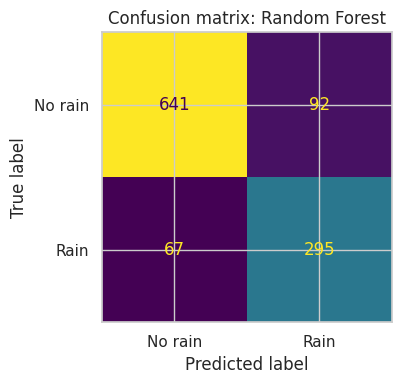

In [ ]:
best_name = clf_results.drop("Baseline (persistence)")["f1"].idxmax()
print("Best classifier by F1:", best_name)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_estimator(fitted_clf[best_name], X_test, yc_test, ax=ax,
                                      display_labels=["No rain", "Rain"], colorbar=False)
ax.set_title(f"Confusion matrix: {best_name}")
plt.tight_layout(); plt.savefig("outputs/04_confusion_matrix.png", dpi=150); plt.show()

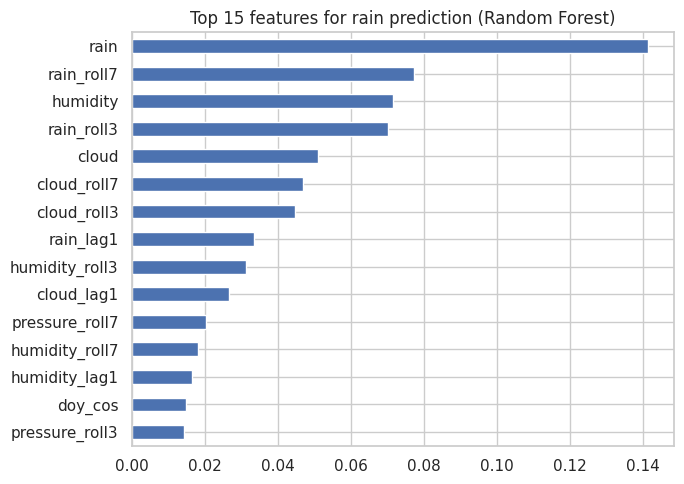

In [ ]:
rf = fitted_clf["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False).head(15)
imp.iloc[::-1].plot(kind="barh", figsize=(7, 5), title="Top 15 features for rain prediction (Random Forest)")
plt.tight_layout(); plt.savefig("outputs/05_feature_importance.png", dpi=150); plt.show()

In [ ]:
# Sanity check: does the score hold across different time periods?
tscv = TimeSeriesSplit(n_splits=5)
cv_f1 = cross_val_score(clf_models["Random Forest"], data[features], data["rain_tomorrow"],
                        cv=tscv, scoring="f1")
print("Time-series CV F1 per fold:", cv_f1.round(3), "| mean:", cv_f1.mean().round(3))

Time-series CV F1 per fold: [0.742 0.766 0.787 0.732 0.831] | mean: 0.771


## 8. Task B: Tomorrow's maximum temperature (regression)

In [ ]:
def reg_metrics(name, y_true, y_pred):
    return {"model": name,
            "MAE (C)": mean_absolute_error(y_true, y_pred),
            "RMSE (C)": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

rres = [reg_metrics("Baseline (persistence)", yr_test, test["temp_max"])]
reg_models = {
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
fitted_reg = {}
for name, model in reg_models.items():
    model.fit(X_train, yr_train)
    fitted_reg[name] = model
    rres.append(reg_metrics(name, yr_test, model.predict(X_test)))

reg_results = pd.DataFrame(rres).set_index("model").round(3)
reg_results.to_csv("outputs/regression_results.csv")
reg_results

,MAE (C),RMSE (C),R2
model,,,
Baseline (persistence),0.882,1.233,0.867
Ridge Regression,0.876,1.164,0.882
Random Forest,0.864,1.172,0.880
Gradient Boosting,0.870,1.171,0.880


Best regressor by MAE: Random Forest


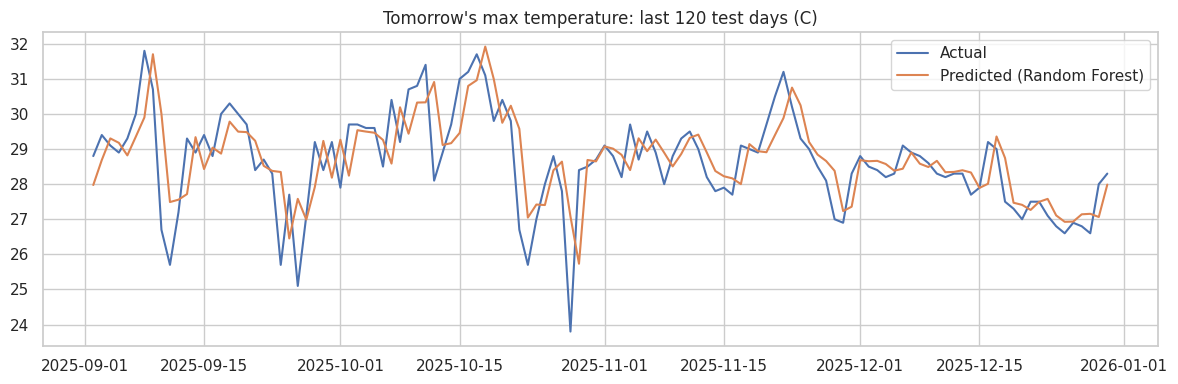

In [ ]:
best_reg = reg_results.drop("Baseline (persistence)")["MAE (C)"].idxmin()
print("Best regressor by MAE:", best_reg)
pred = fitted_reg[best_reg].predict(X_test)
last = slice(-120, None)
plt.figure(figsize=(12, 4))
plt.plot(test.index[last], yr_test.values[last], label="Actual", lw=1.5)
plt.plot(test.index[last], pred[last], label=f"Predicted ({best_reg})", lw=1.5)
plt.title("Tomorrow's max temperature: last 120 test days (C)"); plt.legend()
plt.tight_layout(); plt.savefig("outputs/06_temp_forecast.png", dpi=150); plt.show()

## 9. Save the best models

In [ ]:
os.makedirs("models", exist_ok=True)
joblib.dump(fitted_clf[best_name], "models/rain_classifier.joblib")
joblib.dump(fitted_reg[best_reg], "models/temp_regressor.joblib")
print("Saved models to ./models")

Saved models to ./models
